<a href="https://colab.research.google.com/github/scudilio/AI---Deep-Learning/blob/main/Aula%202/MBA_DL_Aula_2_01_colab_transfer_learning_fotos.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Aula 1 | Momento uau: Transfer Learning com uma rede pré-treinada (MobileNetV2)

### MBA FIAP | Deep Learning e Redes Neurais Modernas | Profa. Juliana Scudilio

**O problema.** No notebook da CNN treinamos uma rede **do zero** com 9.000 fotos e chegamos perto de 60% de acerto. Na vida real raramente temos 9.000 fotos rotuladas de cada coisa. Temos 100. Ou 10.

**A ideia.** A MobileNetV2 é uma rede que já foi treinada na ImageNet (1,2 milhão de fotos, 1.000 categorias). Ela já sabe enxergar bordas, texturas e partes de objetos. Em vez de ensinar tudo de novo, **reaproveitamos** essa rede e ensinamos só o final. Isso é **transfer learning**.

Vamos fazer de dois jeitos, com apenas **100 fotos por classe**:

1. **Sem fine-tuning**: a rede pré-treinada fica **congelada**. Só a camada nova do final aprende.
2. **Com fine-tuning**: **liberamos as últimas camadas** da rede para também se ajustarem às nossas fotos, com passos bem pequenos.

Roda no Google Colab, em CPU (uns 6 minutos de treino no total). Com GPU (Ambiente de execução → Alterar tipo de ambiente de execução) é bem mais rápido.

In [13]:
import os, time, zipfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
import keras

print("Keras", keras.__version__)

Keras 3.13.2


## 1. Carregar as fotos do arquivo zip

O arquivo `cifar10_amostra_1.zip` tem a estrutura abaixo: uma pasta de fotos e uma planilha de rótulos, do jeito que um dataset de imagens chega numa empresa.

```
train/imagem_000.png ... (10.000 fotos)
test/imagem_000.png  ... (2.000 fotos)
rotulos.csv           colunas: arquivo, classe (0 a 9), nome_classe
```

Rode a célula e envie o zip quando o seletor de arquivos abrir (se o arquivo já estiver na pasta, a célula usa direto).

In [14]:
if not os.path.exists("cifar10_amostra.zip"):
    from google.colab import files
    files.upload()                                   # escolha o arquivo cifar10_amostra_1.zip no seu computador

with zipfile.ZipFile("cifar10_amostra.zip") as z:
    z.extractall("fotos")                            # descompacta na pasta "fotos"

rotulos = pd.read_csv("fotos/rotulos.csv")
print("Total de fotos:", len(rotulos))
rotulos.head()

Total de fotos: 12000


,arquivo,classe,nome_classe
0,train/imagem_000.png,0,aviao
1,train/imagem_001.png,4,cervo
2,train/imagem_002.png,0,aviao
3,train/imagem_003.png,6,sapo
4,train/imagem_004.png,7,cavalo


In [15]:
# separando as linhas de treino e de teste pela pasta de origem
treino = rotulos[rotulos["arquivo"].str.startswith("train/")]
teste  = rotulos[rotulos["arquivo"].str.startswith("test/")]

# lendo cada PNG e guardando como array de números (32 x 32 pixels x 3 cores)
x_train_todos = np.array([np.asarray(Image.open("fotos/" + arq).convert("RGB")) for arq in treino["arquivo"]])
y_train_todos = treino["classe"].to_numpy()

x_test = np.array([np.asarray(Image.open("fotos/" + arq).convert("RGB")) for arq in teste["arquivo"]])
y_test = teste["classe"].to_numpy()

nomes = ["avião", "carro", "pássaro", "gato", "cervo", "cachorro", "sapo", "cavalo", "navio", "caminhão"]

print("Treino:", x_train_todos.shape, "| Teste:", x_test.shape)
print("Cada foto:", x_train_todos.shape[1:], "(altura x largura x cores) | valores de", x_train_todos.min(), "a", x_train_todos.max())

Treino: (10000, 32, 32, 3) | Teste: (2000, 32, 32, 3)
Cada foto: (32, 32, 3) (altura x largura x cores) | valores de 0 a 255


## 2. Usar poucas fotos por classe

Temos cerca de 1.000 fotos de treino por classe. De propósito, vamos usar **só 100** por classe para treinar e 50 para validar. O teste são as mesmas 2.000 fotos do notebook da CNN, para comparar.

In [16]:
POR_CLASSE = 100          # troque para 10 ou 300 e veja o efeito

rng = np.random.default_rng(0)
indices = []
for c in range(10):
    fotos_da_classe = np.where(y_train_todos == c)[0]
    indices.extend(rng.choice(fotos_da_classe, POR_CLASSE + 50, replace=False))   # 100 para treino + 50 para validação
indices = rng.permutation(indices)

x_valid, y_valid = x_train_todos[indices[:500]], y_train_todos[indices[:500]]
x_train, y_train = x_train_todos[indices[500:]], y_train_todos[indices[500:]]

print("Treinamento:", len(x_train), "fotos (", POR_CLASSE, "por classe )")
print("Validação:  ", len(x_valid), "fotos")
print("Teste:      ", len(x_test), "fotos")

Treinamento: 1000 fotos ( 100 por classe )
Validação:   500 fotos
Teste:       2000 fotos


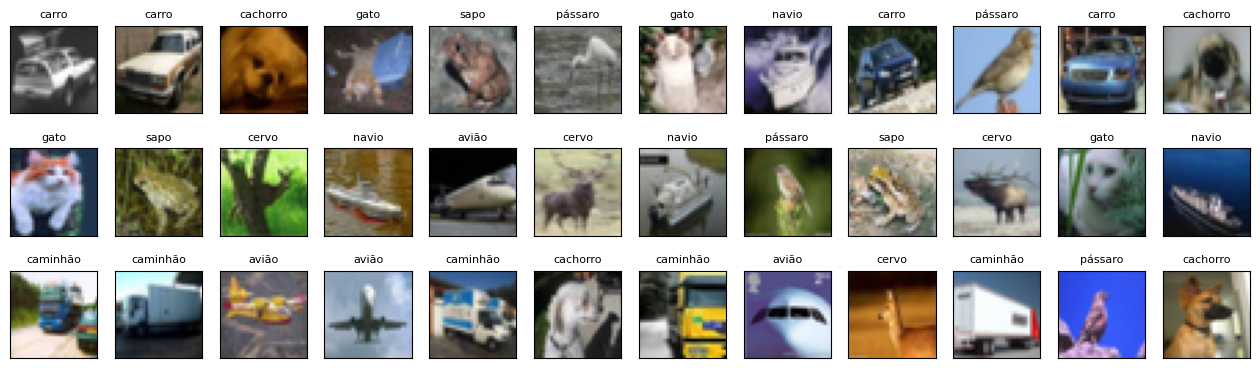

In [17]:
# as 36 primeiras fotos do treino
fig = plt.figure(figsize=(16, 4.5))
for i in range(36):
    ax = fig.add_subplot(3, 12, i + 1, xticks=[], yticks=[])
    ax.imshow(x_train[i]); ax.set_title(nomes[y_train[i]], fontsize=8)
plt.show()

In [18]:
from keras.utils import to_categorical
# rótulos em one-hot (como no notebook da CNN). Os pixels ficam de 0 a 255: a normalização vai dentro do modelo.
y_train = to_categorical(y_train, 10)
y_valid = to_categorical(y_valid, 10)
y_test  = to_categorical(y_test, 10)

## 3. Carregar a rede pré-treinada

A MobileNetV2 vem com os pesos aprendidos na ImageNet. Carregamos **sem a última camada** (`include_top=False`): a última decide entre as 1.000 classes da ImageNet, e nós queremos 10.

Ela foi treinada com fotos grandes; vamos usar 160 x 160 pixels e esticar as nossas fotos de 32 x 32 para esse tamanho.

In [19]:
from keras.applications import MobileNetV2

base = MobileNetV2(weights="imagenet", include_top=False, input_shape=(160, 160, 3), pooling="avg")

print("Camadas na MobileNetV2:", len(base.layers))
print("Parâmetros já treinados:", f"{base.count_params():,}")

Camadas na MobileNetV2: 155
Parâmetros já treinados: 2,257,984


## 4. Montar o modelo: rede pré-treinada + uma camada nova

```
foto 32x32  →  esticar para 160x160  →  escala de -1 a 1  →  MobileNetV2  →  Dense(10, softmax)
```

A única parte nova é a `Dense(10)`: ela recebe os 1.280 números que a MobileNetV2 devolve para cada foto e decide entre as 10 classes.

In [20]:
from keras.models import Sequential
from keras.layers import Input, Resizing, Rescaling, Dropout, Dense

model = Sequential([
    Input(shape=(32, 32, 3)),
    Resizing(160, 160),                          # estica a foto para o tamanho que a MobileNetV2 espera
    Rescaling(1.0 / 127.5, offset=-1),           # pixels de 0..255 para -1..1 (a escala da MobileNetV2)
    base,                                        # a rede pré-treinada inteira
    Dropout(0.2),
    Dense(10, activation="softmax")              # a camada nova: 10 classes
])

## 5. Parte 1: SEM fine-tuning (rede congelada)

**Congelar** uma camada é dizer ao Keras: *não mexa nesses pesos durante o treino*. Fazemos isso com `trainable = False`.

Congelamos a MobileNetV2 inteira. Só a `Dense(10)` vai aprender. Veja no resumo quantos pesos ficam treináveis.

In [21]:
base.trainable = False        # congela a MobileNetV2 inteira: nenhum dos pesos dela muda no treino

model.compile(loss="categorical_crossentropy", optimizer="adam", metrics=["accuracy"])
model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ resizing_1 (Resizing)           │ (None, 160, 160, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling_1 (Rescaling)         │ (None, 160, 160, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_160            │ (None, 1280)           │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │        12,810 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,270,794 (8.66 MB)

 Trainable params: 12,810 (50.04 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [22]:
inicio = time.time()
historico1 = model.fit(x_train, y_train, batch_size=32, epochs=5, validation_data=(x_valid, y_valid), verbose=1)
print(f"Tempo: {time.time() - inicio:.0f} segundos")


Epoch 1/5
32/32 ━━━━━━━━━━━━━━━━━━━━ 38s 1s/step - accuracy: 0.3320 - loss: 2.0229 - val_accuracy: 0.6120 - val_loss: 1.1663
Epoch 2/5
32/32 ━━━━━━━━━━━━━━━━━━━━ 29s 930ms/step - accuracy: 0.6750 - loss: 0.9801 - val_accuracy: 0.6960 - val_loss: 0.8503
Epoch 3/5
32/32 ━━━━━━━━━━━━━━━━━━━━ 31s 982ms/step - accuracy: 0.7670 - loss: 0.6940 - val_accuracy: 0.7240 - val_loss: 0.7854
Epoch 4/5
32/32 ━━━━━━━━━━━━━━━━━━━━ 42s 1s/step - accuracy: 0.8140 - loss: 0.5832 - val_accuracy: 0.7280 - val_loss: 0.7484
Epoch 5/5
32/32 ━━━━━━━━━━━━━━━━━━━━ 31s 961ms/step - accuracy: 0.8500 - loss: 0.4746 - val_accuracy: 0.7320 - val_loss: 0.7318
Tempo: 182 segundos


In [23]:

perda, acc_sem = model.evaluate(x_test, y_test, verbose=0)
print(f"Acurácia de teste SEM fine-tuning: {acc_sem*100:.1f} %")

Acurácia de teste SEM fine-tuning: 77.7 %


Compare com a CNN do zero: 9.000 fotos e todos os pesos treinados deram perto de 60%. Aqui foram 1.000 fotos e só 12.810 pesos treinados.

## 6. Parte 2: COM fine-tuning (liberar as últimas camadas)

Agora deixamos **as últimas camadas** da MobileNetV2 se ajustarem às nossas fotos. Duas regras:

1. **Liberar só o final.** As primeiras camadas aprendem bordas e texturas, que servem para qualquer foto. As últimas são as mais específicas. Liberamos as últimas 30 das 155 camadas.
2. **Passos bem pequenos** (`learning_rate=0.00001`). Os pesos já são bons; queremos ajustar, não destruir. Com passo grande a rede "esquece" o que sabia (esquecimento catastrófico).

O laço abaixo mostra exatamente o que é congelado e o que é liberado.

In [24]:
base.trainable = True                            # primeiro libera tudo...

for camada in base.layers[:-30]:                 # ...depois congela de novo todas as camadas, menos as últimas 30
    camada.trainable = False

# conferindo: quantas camadas ficaram congeladas e quantas liberadas
congeladas = sum(1 for c in base.layers if not c.trainable)
liberadas  = sum(1 for c in base.layers if c.trainable)
print("Camadas congeladas:", congeladas, "| camadas liberadas:", liberadas)
print("Últimas camadas liberadas:", [c.name for c in base.layers[-5:]])

from keras.optimizers import Adam
model.compile(loss="categorical_crossentropy", optimizer=Adam(learning_rate=0.00001), metrics=["accuracy"])   # recompilar é obrigatório
model.summary()

Camadas congeladas: 125 | camadas liberadas: 30
Últimas camadas liberadas: ['block_16_project_BN', 'Conv_1', 'Conv_1_bn', 'out_relu', 'global_average_pooling2d_1']


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ resizing_1 (Resizing)           │ (None, 160, 160, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling_1 (Rescaling)         │ (None, 160, 160, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_160            │ (None, 1280)           │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │        12,810 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,270,794 (8.66 MB)

 Trainable params: 1,538,890 (5.87 MB)

 Non-trainable params: 731,904 (2.79 MB)

Repare no resumo: os pesos treináveis saltaram de cerca de 12 mil para cerca de 1,5 milhão. As últimas 30 camadas são as mais largas da rede.

In [25]:
inicio = time.time()
historico2 = model.fit(x_train, y_train, batch_size=32, epochs=5, validation_data=(x_valid, y_valid), verbose=1)
print(f"Tempo: {time.time() - inicio:.0f} segundos")

perda, acc_com = model.evaluate(x_test, y_test, verbose=0)
print(f"Acurácia de teste COM fine-tuning: {acc_com*100:.1f} %")

Epoch 1/5
32/32 ━━━━━━━━━━━━━━━━━━━━ 49s 1s/step - accuracy: 0.6850 - loss: 0.9525 - val_accuracy: 0.7280 - val_loss: 0.7261
Epoch 2/5
32/32 ━━━━━━━━━━━━━━━━━━━━ 38s 1s/step - accuracy: 0.7520 - loss: 0.7841 - val_accuracy: 0.7340 - val_loss: 0.7241
Epoch 3/5
32/32 ━━━━━━━━━━━━━━━━━━━━ 41s 1s/step - accuracy: 0.7830 - loss: 0.6738 - val_accuracy: 0.7240 - val_loss: 0.7283
Epoch 4/5
32/32 ━━━━━━━━━━━━━━━━━━━━ 39s 1s/step - accuracy: 0.8180 - loss: 0.6001 - val_accuracy: 0.7260 - val_loss: 0.7289
Epoch 5/5
32/32 ━━━━━━━━━━━━━━━━━━━━ 37s 1s/step - accuracy: 0.8590 - loss: 0.4897 - val_accuracy: 0.7260 - val_loss: 0.7270
Tempo: 208 segundos
Acurácia de teste COM fine-tuning: 77.7 %


## 7. Comparar as três abordagens

Preencha `ACURACIA_CNN_DO_ZERO` com o número que você obteve no notebook da CNN.

In [26]:
ACURACIA_CNN_DO_ZERO = 59.5     # troque pelo seu número (em %)

print(f"{'Abordagem':<40} {'fotos de treino':>16} {'acurácia teste':>15}")
print(f"{'CNN do zero (notebook anterior)':<40} {9000:>16} {ACURACIA_CNN_DO_ZERO:>14.1f}%")
print(f"{'MobileNetV2 congelada (sem fine-tuning)':<40} {len(x_train):>16} {acc_sem*100:>14.1f}%")
print(f"{'MobileNetV2 com fine-tuning':<40} {len(x_train):>16} {acc_com*100:>14.1f}%")

Abordagem                                 fotos de treino  acurácia teste
CNN do zero (notebook anterior)                      9000           59.5%
MobileNetV2 congelada (sem fine-tuning)              1000           77.7%
MobileNetV2 com fine-tuning                          1000           77.7%


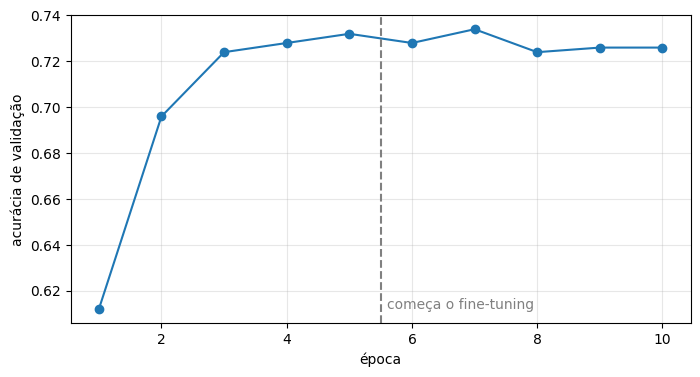

In [27]:
# acurácia de validação ao longo das 10 épocas (5 congelada + 5 com fine-tuning)
acc_val = historico1.history["val_accuracy"] + historico2.history["val_accuracy"]
plt.figure(figsize=(8, 4))
plt.plot(range(1, 11), acc_val, marker="o")
plt.axvline(5.5, color="gray", linestyle="--"); plt.text(5.6, min(acc_val), "começa o fine-tuning", color="gray")
plt.xlabel("época"); plt.ylabel("acurácia de validação"); plt.grid(alpha=.3); plt.show()

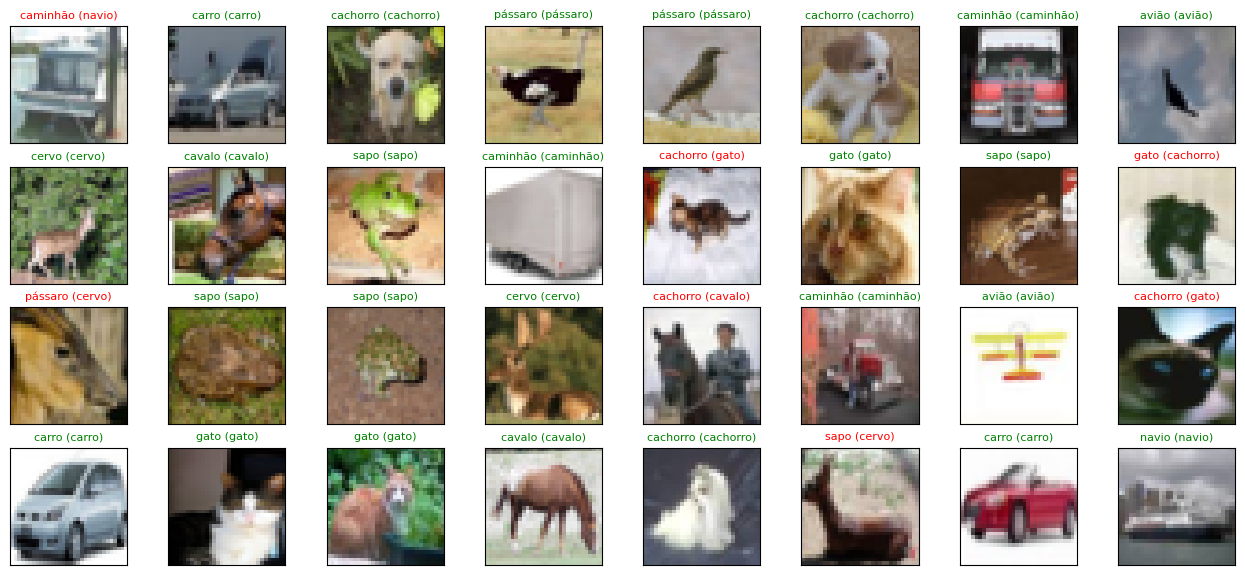

In [28]:
# algumas previsões no teste: verde acertou, vermelho errou
previsoes = model.predict(x_test[:32], verbose=0).argmax(axis=1)
reais = y_test[:32].argmax(axis=1)

fig = plt.figure(figsize=(16, 7))
for i in range(32):
    ax = fig.add_subplot(4, 8, i + 1, xticks=[], yticks=[])
    ax.imshow(x_test[i])
    ax.set_title(f"{nomes[previsoes[i]]} ({nomes[reais[i]]})", color="green" if previsoes[i] == reais[i] else "red", fontsize=8)
plt.show()

## O que acabou de acontecer

| | CNN do zero | Sem fine-tuning | Com fine-tuning |
|---|---|---|---|
| O que treina | tudo (356 mil pesos) | só a camada nova (12 mil pesos) | camada nova + últimas 30 camadas (1,5 milhão) |
| Fotos | 9.000 | 1.000 | 1.000 |
| Quando usar | problema muito diferente de fotos comuns, e muito dado | poucos dados, pouco tempo | quando "sem fine-tuning" chega perto e vale ajustar o resto |

**Por que funciona?** As primeiras camadas de qualquer CNN aprendem bordas e texturas; isso é igual em fotos de gatos, de peças ou de raio-X. Só o final é específico. Reaproveitar o começo é reaproveitar o trabalho mais caro.

**Por que não deu 95%?** As fotos têm 32 x 32 pixels, esticadas para 160 x 160; a MobileNetV2 viu fotos nítidas na ImageNet. Com fotos reais do seu negócio o ganho costuma ser maior.

## Para discutir

1. Troque `POR_CLASSE` para 10 e rode de novo. Com 10 fotos por classe, quanto a rede acerta?
2. Troque `base.layers[:-30]` por `base.layers[:-60]` (libera mais camadas) ou `learning_rate=0.001` (passo maior). O que acontece? Esse é o esquecimento catastrófico ao vivo.
3. Que problema da sua empresa tem "poucas fotos por classe"? (defeito raro, produto novo, documento incomum)